In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
          "GB")
else:
    print("No GPU assigned.")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 15.64 GB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ByeByeLanternfly"

folders = [
    "datasets",
    "models",
    "results",
    "checkpoints",
    "reports"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project directories created!")
print(PROJECT_DIR)

Project directories created!
/content/drive/MyDrive/ByeByeLanternfly


In [ ]:
!pip install -q ultralytics

import torch
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.202
CUDA: True
GPU: Tesla T4


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/ByeByeLanternfly/datasets/lanternfly_v4_upload.zip"

DATASET_DIR = "/content/lanternfly_v4"

os.makedirs(DATASET_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_DIR)

print("Dataset extracted!")
print(os.listdir(DATASET_DIR))

Dataset extracted!
['labels\\train\\rf_ead985d862ae8a69bc4c.txt', 'labels\\train\\rf_04eab4ec9e6915ab79b8.txt', 'images\\train\\rf_82741bb6324494f329a6.jpg', 'images\\test\\rf_8d8ec52cc449ffa6f4f8.jpg', 'images\\train\\rf_13f1c54c8485f0682b47.jpg', 'images\\train\\rf_a520eeadef00dd35cb57.jpg', 'labels\\train\\rf_ffc8e4623af789d46fcf.txt', 'labels\\val\\rf_fff1facff536d79f6183.txt', 'images\\train\\rf_3b04df6238d6f99527aa.jpg', 'labels\\val\\rf_1e4131b560fd9cf8041d.txt', 'labels\\val\\rf_6e1aa4bf0c21280425c5.txt', 'images\\train\\rf_c8496a27c069b54aae3f.jpg', 'images\\train\\rf_b771a1bc76c03a1de32f.jpg', 'images\\train\\rf_ead985d862ae8a69bc4c.jpg', 'images\\train\\rf_5a738e178324b72661ef.jpg', 'labels\\val\\rf_405428d2d42846a3f563.txt', 'images\\train\\rf_18e7be0453065d1a9665.jpg', 'labels\\train\\rf_eb60b4ddf1d4c4a1d5b6.txt', 'images\\train\\rf_6f5e5210b52bf6a2180e.jpg', 'images\\train\\rf_65b08ab404050c6fe5c6.jpg', 'labels\\train\\rf_02ff2fad0477239c4730.txt', 'images\\train\\rf_d7cc

In [ ]:
data_yaml = f"""
path: {DATASET_DIR}
train: images/train
val: images/val
test: images/test

names:
  0: lanternfly
"""

with open(f"{DATASET_DIR}/data.yaml", "w") as f:
    f.write(data_yaml)

print("YOLO configuration created!")

YOLO configuration created!


In [ ]:

from pathlib import Path
from PIL import Image
from collections import Counter
import yaml

DATASET_DIR = Path("/content/lanternfly_v4")

splits = ["train", "val", "test"]
expected_images = {
    "train": 1827,
    "val": 438,
    "test": 276
}

total_images = 0
total_boxes = 0
errors = []

for split in splits:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    images = sorted(image_dir.glob("*.jpg"))
    labels = sorted(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    missing_labels = image_stems - label_stems
    missing_images = label_stems - image_stems

    boxes = 0

    for label_file in labels:
        with open(label_file, "r") as f:
            for line in f:
                values = line.strip().split()

                if not values:
                    continue

                if len(values) != 5:
                    errors.append(
                        f"Invalid format: {label_file.name}"
                    )
                    continue

                try:
                    cls, x, y, w, h = map(float, values)

                    if cls != 0:
                        errors.append(
                            f"Unexpected class: {label_file.name}"
                        )

                    if not (
                        0 <= x <= 1 and
                        0 <= y <= 1 and
                        0 < w <= 1 and
                        0 < h <= 1
                    ):
                        errors.append(
                            f"Invalid bounding box: {label_file.name}"
                        )

                    boxes += 1

                except ValueError:
                    errors.append(
                        f"Invalid numeric label: {label_file.name}"
                    )

    unreadable = []

    for image_path in images:
        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            unreadable.append(image_path.name)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Bounding boxes:", boxes)
    print("Missing labels:", len(missing_labels))
    print("Missing images:", len(missing_images))
    print("Unreadable images:", len(unreadable))

    if len(images) != expected_images[split]:
        errors.append(f"Unexpected image count in {split}")

    if missing_labels or missing_images or unreadable:
        errors.append(f"File integrity issue in {split}")

    total_images += len(images)
    total_boxes += boxes

print("\n-------------------------")
print("TOTAL IMAGES:", total_images)
print("TOTAL BOXES:", total_boxes)
print("VALIDATION ERRORS:", len(errors))

for error in errors[:30]:
    print("ERROR:", error)

if errors:
    print("\nDATASET NEEDS ATTENTION")
else:
    print("\nDATASET STRUCTURALLY VERIFIED")



TRAIN
Images: 0
Labels: 0
Bounding boxes: 0
Missing labels: 0
Missing images: 0
Unreadable images: 0

VAL
Images: 0
Labels: 0
Bounding boxes: 0
Missing labels: 0
Missing images: 0
Unreadable images: 0

TEST
Images: 0
Labels: 0
Bounding boxes: 0
Missing labels: 0
Missing images: 0
Unreadable images: 0

-------------------------
TOTAL IMAGES: 0
TOTAL BOXES: 0
VALIDATION ERRORS: 3
ERROR: Unexpected image count in train
ERROR: Unexpected image count in val
ERROR: Unexpected image count in test

DATASET NEEDS ATTENTION


In [ ]:

from pathlib import Path

root = Path("/content/lanternfly_v4")

print("Root exists:", root.exists())
print("\nRoot contents:")

if root.exists():
    for item in root.iterdir():
        print(item.name, "DIRECTORY" if item.is_dir() else "FILE")

print("\nSearching for image folders...")

images_found = list(root.rglob("*.jpg"))

print("Total JPG files found:", len(images_found))

if images_found:
    print("\nFirst 10 image paths:")
    for path in images_found[:10]:
        print(path)

print("\nSearching for dataset YAML files...")

for path in root.rglob("*.yaml"):
    print(path)



Root exists: True

Root contents:
labels\train\rf_ead985d862ae8a69bc4c.txt FILE
labels\train\rf_04eab4ec9e6915ab79b8.txt FILE
images\train\rf_82741bb6324494f329a6.jpg FILE
images\test\rf_8d8ec52cc449ffa6f4f8.jpg FILE
images\train\rf_13f1c54c8485f0682b47.jpg FILE
images\train\rf_a520eeadef00dd35cb57.jpg FILE
labels\train\rf_ffc8e4623af789d46fcf.txt FILE
labels\val\rf_fff1facff536d79f6183.txt FILE
images\train\rf_3b04df6238d6f99527aa.jpg FILE
labels\val\rf_1e4131b560fd9cf8041d.txt FILE
labels\val\rf_6e1aa4bf0c21280425c5.txt FILE
images\train\rf_c8496a27c069b54aae3f.jpg FILE
images\train\rf_b771a1bc76c03a1de32f.jpg FILE
images\train\rf_ead985d862ae8a69bc4c.jpg FILE
images\train\rf_5a738e178324b72661ef.jpg FILE
labels\val\rf_405428d2d42846a3f563.txt FILE
images\train\rf_18e7be0453065d1a9665.jpg FILE
labels\train\rf_eb60b4ddf1d4c4a1d5b6.txt FILE
images\train\rf_6f5e5210b52bf6a2180e.jpg FILE
images\train\rf_65b08ab404050c6fe5c6.jpg FILE
labels\train\rf_02ff2fad0477239c4730.txt FILE
images\tr

In [ ]:

import zipfile
from pathlib import Path, PurePosixPath

ZIP_PATH = Path(
    "/content/drive/MyDrive/ByeByeLanternfly/datasets/lanternfly_v4_upload.zip"
)

FIXED_DIR = Path("/content/lanternfly_v4_fixed")
FIXED_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for member in archive.infolist():

        # Convert Windows separators into Linux separators
        normalized = member.filename.replace("\\", "/")
        relative = PurePosixPath(normalized)

        # Prevent unsafe archive paths
        if relative.is_absolute() or ".." in relative.parts:
            raise ValueError(f"Unsafe archive path: {member.filename}")

        destination = FIXED_DIR.joinpath(*relative.parts)

        if member.is_dir():
            destination.mkdir(parents=True, exist_ok=True)
        else:
            destination.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member) as source:
                with open(destination, "wb") as target:
                    target.write(source.read())

print("Dataset paths normalized!")
print("Corrected dataset location:", FIXED_DIR)
print("Top-level contents:", [p.name for p in FIXED_DIR.iterdir()])


Dataset paths normalized!
Corrected dataset location: /content/lanternfly_v4_fixed
Top-level contents: ['dataset_manifest.json', 'images', 'validation.txt', 'dataset.yaml', 'labels']


In [ ]:

from pathlib import Path
from PIL import Image

splits = ["train", "val", "test"]

expected_images = {
    "train": 1827,
    "val": 438,
    "test": 276
}

total_images = 0
total_boxes = 0
errors = []

for split in splits:
    image_dir = FIXED_DIR / "images" / split
    label_dir = FIXED_DIR / "labels" / split

    images = list(image_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    missing_labels = image_stems - label_stems
    missing_images = label_stems - image_stems

    boxes = 0

    for label_file in labels:
        for line in label_file.read_text().splitlines():
            if not line.strip():
                continue

            values = line.split()

            if len(values) != 5:
                errors.append(f"Invalid label: {label_file.name}")
                continue

            try:
                cls, x, y, w, h = map(float, values)

                if cls != 0:
                    errors.append(f"Unexpected class: {label_file.name}")

                if not (
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1
                ):
                    errors.append(f"Invalid box: {label_file.name}")

                boxes += 1

            except ValueError:
                errors.append(f"Invalid numeric data: {label_file.name}")

    unreadable = []

    for img_path in images:
        try:
            with Image.open(img_path) as img:
                img.verify()
        except Exception:
            unreadable.append(img_path.name)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Bounding boxes:", boxes)
    print("Missing labels:", len(missing_labels))
    print("Missing images:", len(missing_images))
    print("Unreadable images:", len(unreadable))

    if len(images) != expected_images[split]:
        errors.append(f"Incorrect image count: {split}")

    if missing_labels or missing_images or unreadable:
        errors.append(f"File integrity problem: {split}")

    total_images += len(images)
    total_boxes += boxes

print("\nTOTAL IMAGES:", total_images)
print("TOTAL BOXES:", total_boxes)
print("ERRORS:", len(errors))

for error in errors[:30]:
    print("ERROR:", error)

print("\nRESULT:", "PASS" if not errors else "NEEDS ATTENTION")



TRAIN
Images: 1827
Labels: 1827
Bounding boxes: 2978
Missing labels: 0
Missing images: 0
Unreadable images: 0

VAL
Images: 438
Labels: 438
Bounding boxes: 788
Missing labels: 0
Missing images: 0
Unreadable images: 0

TEST
Images: 276
Labels: 276
Bounding boxes: 765
Missing labels: 0
Missing images: 0
Unreadable images: 0

TOTAL IMAGES: 2541
TOTAL BOXES: 4531
ERRORS: 0

RESULT: PASS


In [ ]:
!pip install -q ultralytics


In [ ]:
import torch
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    raise RuntimeError("GPU not detected. Check your Colab runtime settings.")

Ultralytics version: 8.4.202
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
from pathlib import Path
from google.colab import drive
import yaml
import torch

# Mount Google Drive if it is not already mounted
drive.mount("/content/drive")

# Verified dataset location
DATASET_DIR = Path("/content/lanternfly_v4_fixed")

# Persistent training output location
DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/ByeByeLanternfly/training_runs"
)
DRIVE_PROJECT.mkdir(parents=True, exist_ok=True)

# Confirm dataset folders exist
required_folders = [
    DATASET_DIR / "images" / "train",
    DATASET_DIR / "images" / "val",
    DATASET_DIR / "images" / "test",
    DATASET_DIR / "labels" / "train",
    DATASET_DIR / "labels" / "val",
    DATASET_DIR / "labels" / "test",
]

for folder in required_folders:
    if not folder.exists():
        raise FileNotFoundError(f"Missing folder: {folder}")

# Create a Linux-compatible YOLO dataset configuration
DATA_YAML = DATASET_DIR / "data.yaml"

dataset_config = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "lanternfly"
    }
}

with open(DATA_YAML, "w") as file:
    yaml.safe_dump(dataset_config, file, sort_keys=False)

# Verify configuration and GPU
print("DATASET:", DATASET_DIR)
print("CONFIGURATION:")
print(DATA_YAML.read_text())

print("TRAIN IMAGES:", len(list((DATASET_DIR / "images/train").glob("*"))))
print("VAL IMAGES:", len(list((DATASET_DIR / "images/val").glob("*"))))
print("TEST IMAGES:", len(list((DATASET_DIR / "images/test").glob("*"))))

print("GPU:", torch.cuda.get_device_name(0))
print("GPU AVAILABLE:", torch.cuda.is_available())
print("OUTPUT DIRECTORY:", DRIVE_PROJECT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATASET: /content/lanternfly_v4_fixed
CONFIGURATION:
path: /content/lanternfly_v4_fixed
train: images/train
val: images/val
test: images/test
names:
  0: lanternfly

TRAIN IMAGES: 1827
VAL IMAGES: 438
TEST IMAGES: 276
GPU: Tesla T4
GPU AVAILABLE: True
OUTPUT DIRECTORY: /content/drive/MyDrive/ByeByeLanternfly/training_runs


SMOKE TEST

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import torch

DATA_YAML = "/content/lanternfly_v4_fixed/data.yaml"

TEST_PROJECT = (
    "/content/drive/MyDrive/ByeByeLanternfly/training_runs"
)

# Load pretrained YOLOv8 nano
model = YOLO("yolov8n.pt")

# Run a short GPU training test
results = model.train(
    data=DATA_YAML,
    epochs=2,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=2,
    amp=True,
    seed=42,
    project=TEST_PROJECT,
    name="smoke_test",
    exist_ok=True,
    plots=True,
    save=True,
    verbose=True
)

print("\nSMOKE TEST FINISHED")
print("Training output:", results.save_dir)
print("GPU:", torch.cuda.get_device_name(0))

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lanternfly_v4_fixed/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_test, nbs=64, nms=None, opset=None, optimize=F

**FULL 100 EPOCH**

In [ ]:
from ultralytics import YOLO
import torch

DATA_YAML = "/content/lanternfly_v4_fixed/data.yaml"

DRIVE_PROJECT = (
    "/content/drive/MyDrive/ByeByeLanternfly/training_runs"
)

# Start from the original pretrained YOLOv8n model
model = YOLO("yolov8n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=20,
    amp=True,
    seed=42,
    project=DRIVE_PROJECT,
    name="yolov8n_v4_gpu_100e",
    exist_ok=True,
    save=True,
    save_period=10,
    plots=True,
    verbose=True
)

print("\nFULL TRAINING FINISHED")
print("Results directory:", results.save_dir)
print("Best model:", results.save_dir / "weights" / "best.pt")
print("GPU:", torch.cuda.get_device_name(0))

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lanternfly_v4_fixed/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_v4_gpu_100e, nbs=64, nms=None, opset=None,

In [ ]:
from ultralytics import YOLO
import torch

MODEL_PATH = (
    "/content/drive/MyDrive/ByeByeLanternfly/"
    "training_runs/yolov8n_v4_gpu_100e/weights/best.pt"
)

DATA_YAML = "/content/lanternfly_v4_fixed/data.yaml"

EVAL_PROJECT = (
    "/content/drive/MyDrive/ByeByeLanternfly/evaluations"
)

# Load the best trained checkpoint
model = YOLO(MODEL_PATH)

# Evaluate on the test split
test_results = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    conf=0.001,
    iou=0.7,
    plots=True,
    project=EVAL_PROJECT,
    name="yolov8n_v4_test",
    exist_ok=True,
    verbose=True
)

print("\n========== TEST RESULTS ==========")

for metric, value in test_results.results_dict.items():
    print(f"{metric}: {value}")

print("\nEvaluation directory:", test_results.save_dir)
print("GPU:", torch.cuda.get_device_name(0))

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 39.0±60.0 MB/s, size: 117.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/lanternfly_v4_fixed/labels/test... 276 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 276/276 678.7it/s 0.4s
val: New cache created: /content/lanternfly_v4_fixed/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.5it/s 7.1s
                   all        276        765      0.868      0.711       0.79      0.463
Speed: 2.0ms preprocess, 10.0ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/drive/MyDrive/ByeByeLanternfly/evaluations/yolov8n_v4_test

======

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import json
import numpy as np

MODEL_PATH = Path(
    "/content/drive/MyDrive/ByeByeLanternfly/"
    "training_runs/yolov8n_v4_gpu_100e/weights/best.pt"
)

TEST_IMAGES = Path("/content/lanternfly_v4_fixed/images/test")
TEST_LABELS = Path("/content/lanternfly_v4_fixed/labels/test")

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ByeByeLanternfly/evaluations/"
    "yolov8n_v4_counting"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIDENCE = 0.20
NMS_IOU = 0.45

model = YOLO(str(MODEL_PATH))

image_paths = sorted(
    list(TEST_IMAGES.glob("*.jpg")) +
    list(TEST_IMAGES.glob("*.jpeg")) +
    list(TEST_IMAGES.glob("*.png"))
)

records = []

for result in model.predict(
    source=str(TEST_IMAGES),
    imgsz=640,
    conf=CONFIDENCE,
    iou=NMS_IOU,
    device=0,
    stream=True,
    verbose=False
):
    image_name = Path(result.path).name
    image_stem = Path(result.path).stem

    label_path = TEST_LABELS / f"{image_stem}.txt"

    if not label_path.exists():
        raise FileNotFoundError(f"Missing label: {label_path}")

    # Count ground-truth adult lanternfly annotations
    with open(label_path, "r") as file:
        actual_count = sum(
            1 for line in file
            if line.strip() and int(line.split()[0]) == 0
        )

    # Count model detections
    predicted_count = (
        len(result.boxes)
        if result.boxes is not None
        else 0
    )

    error = predicted_count - actual_count

    records.append({
        "image": image_name,
        "actual_count": actual_count,
        "predicted_count": predicted_count,
        "error": error,
        "absolute_error": abs(error)
    })

# Create results table
df = pd.DataFrame(records)

# Calculate counting metrics
mae = df["absolute_error"].mean()
rmse = np.sqrt((df["error"] ** 2).mean())
exact_matches = (df["error"] == 0).sum()
within_one = (df["absolute_error"] <= 1).sum()

summary = {
    "model": "YOLOv8n",
    "dataset": "Roboflow Vasudevs v7 adult-only machine-screened v4",
    "test_images": len(df),
    "confidence_threshold": CONFIDENCE,
    "nms_iou_threshold": NMS_IOU,
    "total_actual_lanternflies": int(df["actual_count"].sum()),
    "total_predicted_lanternflies": int(df["predicted_count"].sum()),
    "count_mae": float(mae),
    "count_rmse": float(rmse),
    "exact_count_images": int(exact_matches),
    "exact_count_percentage": float(exact_matches / len(df) * 100),
    "within_one_count_images": int(within_one),
    "within_one_count_percentage": float(within_one / len(df) * 100),
    "overcounted_images": int((df["error"] > 0).sum()),
    "undercounted_images": int((df["error"] < 0).sum()),
    "exactly_counted_images": int((df["error"] == 0).sum())
}

# Save individual image counts and summary
df.to_csv(OUTPUT_DIR / "test_count_results.csv", index=False)

with open(OUTPUT_DIR / "counting_summary.json", "w") as file:
    json.dump(summary, file, indent=4)

print("========== COUNTING EVALUATION ==========")

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nResults saved to:", OUTPUT_DIR)

========== COUNTING EVALUATION ==========
model: YOLOv8n
dataset: Roboflow Vasudevs v7 adult-only machine-screened v4
test_images: 276
confidence_threshold: 0.2
nms_iou_threshold: 0.45
total_actual_lanternflies: 765
total_predicted_lanternflies: 696
count_mae: 0.4673913043478261
count_rmse: 3.1027103626028163
exact_count_images: 246
exact_count_percentage: 89.13043478260869
within_one_count_images: 263
within_one_count_percentage: 95.28985507246377
overcounted_images: 17
undercounted_images: 13
exactly_counted_images: 246

Results saved to: /content/drive/MyDrive/ByeByeLanternfly/evaluations/yolov8n_v4_counting


In [ ]:
import pandas as pd
import numpy as np

CSV_PATH = (
    "/content/drive/MyDrive/ByeByeLanternfly/"
    "evaluations/yolov8n_v4_counting/test_count_results.csv"
)

df = pd.read_csv(CSV_PATH)

df["absolute_error"] = df["error"].abs()

print("========== COUNT ERROR DISTRIBUTION ==========")

print("\nAbsolute error frequency:")
print(df["absolute_error"].value_counts().sort_index())

print("\nError statistics:")
print(df["error"].describe())

print("\nMean signed error:", df["error"].mean())
print("Largest overcount:", df["error"].max())
print("Largest undercount:", df["error"].min())

print("\n========== 15 LARGEST COUNTING ERRORS ==========")

worst_cases = df.sort_values(
    "absolute_error", ascending=False
).head(15)

print(
    worst_cases[
        ["image", "actual_count", "predicted_count",
         "error", "absolute_error"]
    ].to_string(index=False)
)

========== COUNT ERROR DISTRIBUTION ==========

Absolute error frequency:
absolute_error
0     246
1      17
2       6
3       1
4       2
9       1
17      1
21      1
42      1
Name: count, dtype: int64

Error statistics:
count    276.00000
mean      -0.25000
std        3.09824
min      -42.00000
25%        0.00000
50%        0.00000
75%        0.00000
max        4.00000
Name: error, dtype: float64

Mean signed error: -0.25
Largest overcount: 4
Largest undercount: -42

========== 15 LARGEST COUNTING ERRORS ==========
                      image  actual_count  predicted_count  error  absolute_error
rf_e3ccc4427ad998647156.jpg            42                0    -42              42
rf_6cf408d7329629f195ff.jpg            25                4    -21              21
rf_80f72d5a3b7fb59aa5c1.jpg           106               89    -17              17
rf_be5b1ac2b718c878dcd5.jpg            84               75     -9               9
rf_9db138d95b70022611a5.jpg             1                5      4

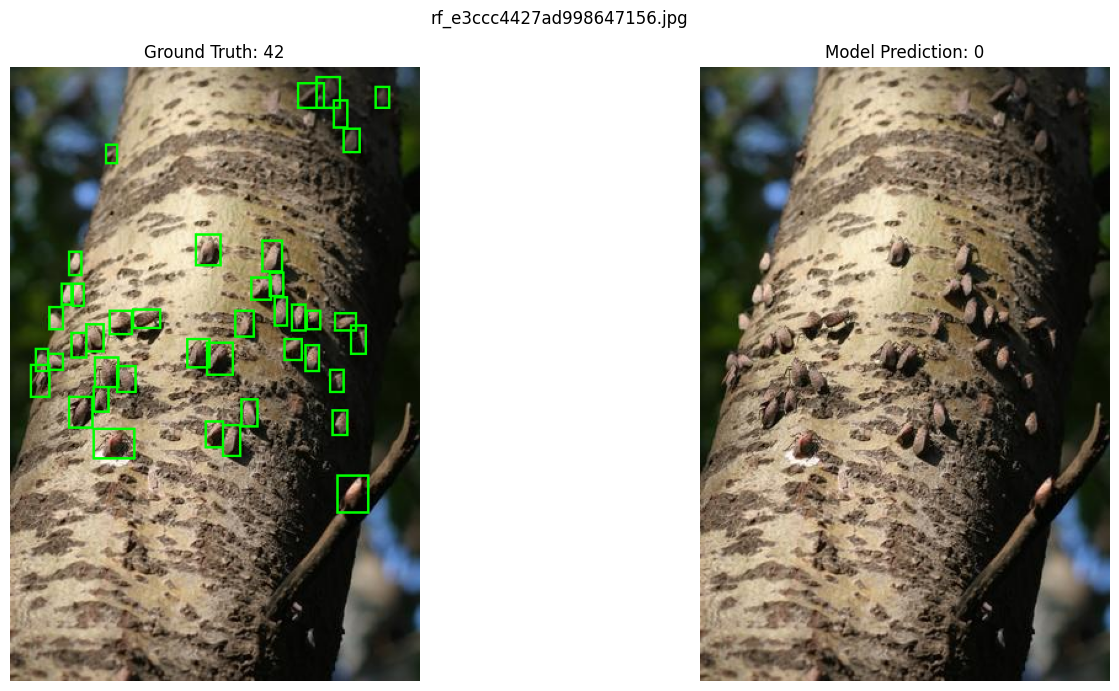

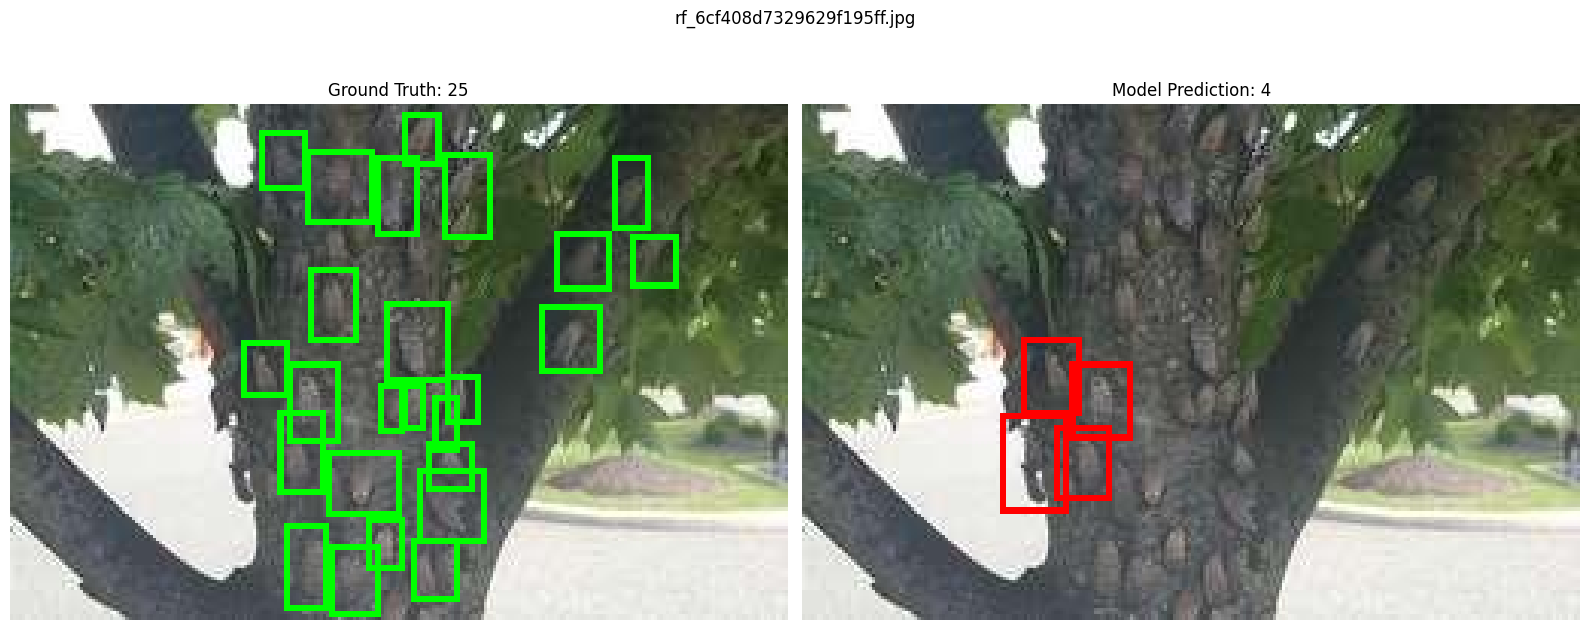

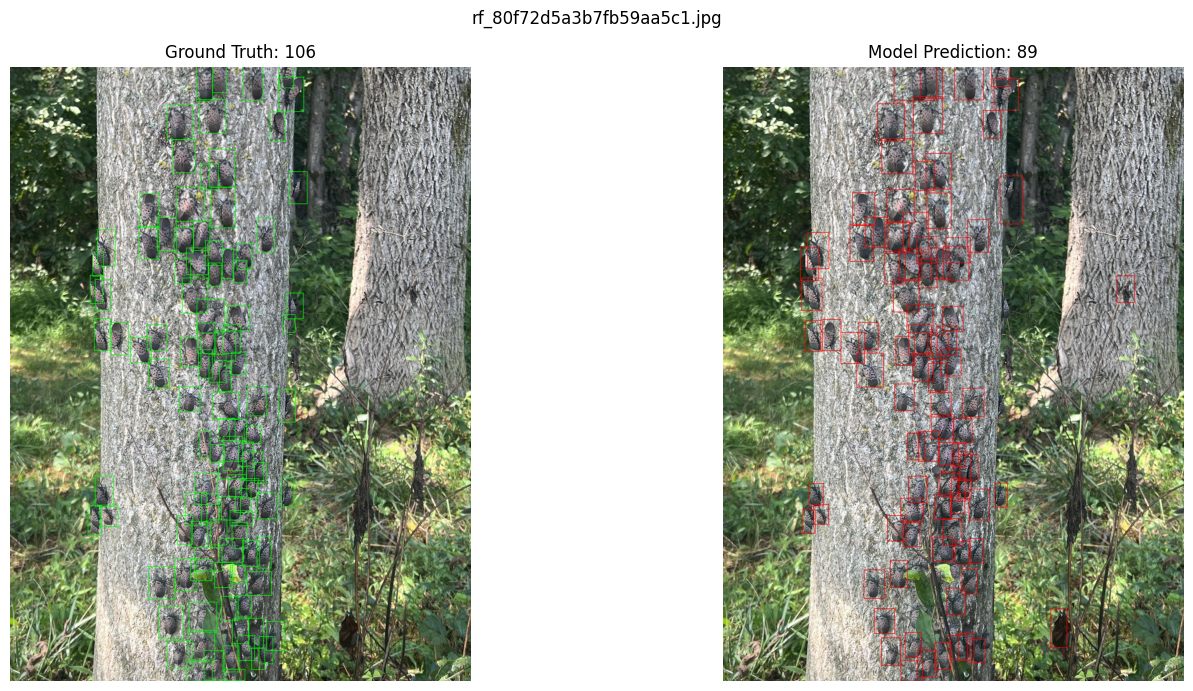

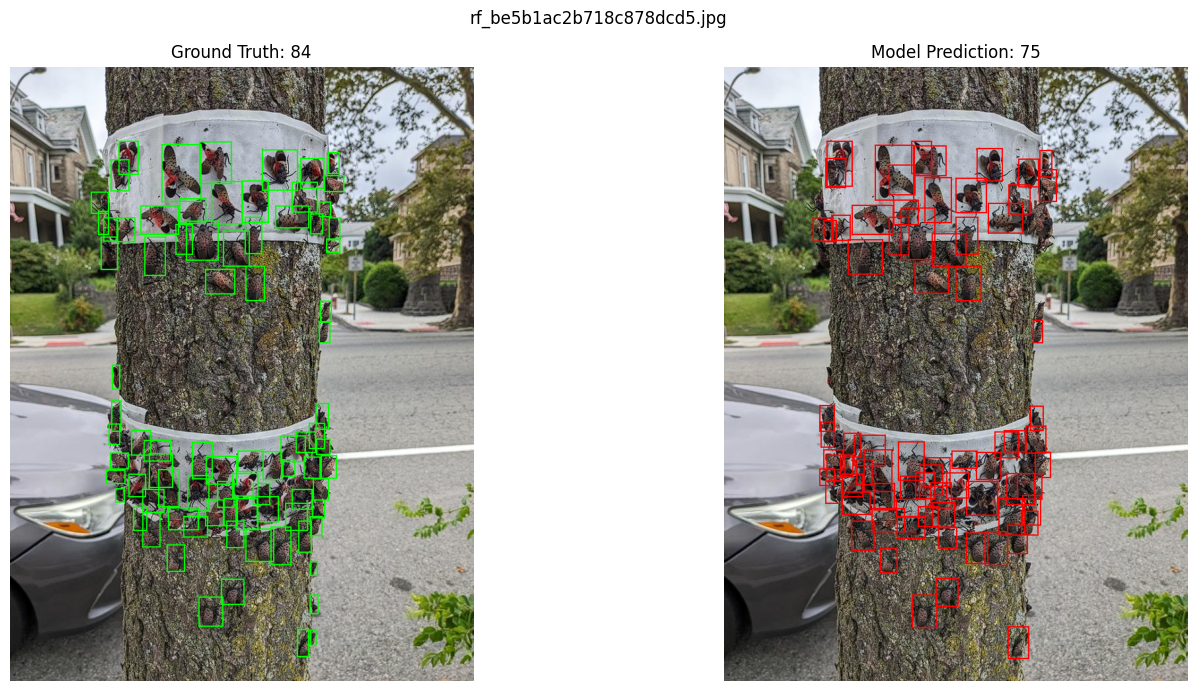

In [ ]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

MODEL_PATH = (
    "/content/drive/MyDrive/ByeByeLanternfly/"
    "training_runs/yolov8n_v4_gpu_100e/weights/best.pt"
)

IMAGE_DIR = Path("/content/lanternfly_v4_fixed/images/test")
LABEL_DIR = Path("/content/lanternfly_v4_fixed/labels/test")

worst_images = [
    "rf_e3ccc4427ad998647156.jpg",
    "rf_6cf408d7329629f195ff.jpg",
    "rf_80f72d5a3b7fb59aa5c1.jpg",
    "rf_be5b1ac2b718c878dcd5.jpg"
]

model = YOLO(MODEL_PATH)

for filename in worst_images:

    image_path = IMAGE_DIR / filename
    label_path = LABEL_DIR / (image_path.stem + ".txt")

    original = Image.open(image_path).convert("RGB")
    width, height = original.size

    # Ground-truth annotation visualization
    ground_truth = original.copy()
    gt_draw = ImageDraw.Draw(ground_truth)

    with open(label_path, "r") as file:
        for line in file:
            values = line.split()

            if len(values) != 5:
                continue

            class_id, xc, yc, bw, bh = map(float, values)

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            gt_draw.rectangle(
                [x1, y1, x2, y2],
                outline="lime",
                width=2
            )

    # Model prediction visualization
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.20,
        iou=0.45,
        device=0,
        verbose=False
    )[0]

    predicted = original.copy()
    pred_draw = ImageDraw.Draw(predicted)

    if result.boxes is not None:
        for box in result.boxes.xyxy.cpu().numpy():
            x1, y1, x2, y2 = box

            pred_draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=2
            )

    actual_count = sum(
        1 for line in label_path.read_text().splitlines()
        if line.strip()
    )

    predicted_count = (
        len(result.boxes) if result.boxes is not None else 0
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    axes[0].imshow(ground_truth)
    axes[0].set_title(f"Ground Truth: {actual_count}")
    axes[0].axis("off")

    axes[1].imshow(predicted)
    axes[1].set_title(f"Model Prediction: {predicted_count}")
    axes[1].axis("off")

    fig.suptitle(filename)
    plt.tight_layout()
    plt.show()

In [ ]:
from google.colab import files

MODEL_PATH = (
    "/content/drive/MyDrive/ByeByeLanternfly/"
    "training_runs/yolov8n_v4_gpu_100e/weights/best.pt"
)

files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>